# W1 — Weekly sales: data and inputs

Additional experiment: the same M5 series forecast at the weekly level. This notebook describes the weekly
data and the inputs of the weekly global model (`src/weekly.py`); the models are in W2 and the comparison
with the classical methods in W3.

**Weeks.** Monday to Sunday. Week 1 starts on 31.01.2011 (the two days before it are dropped), so that the
last training day, 24.04.2016, the last validation day, 22.05.2016, and the last test day, 19.06.2016, are
Sundays. The forecast origins of the daily models are therefore week ends, and weekly sums of daily
forecasts can be compared with weekly forecasts. The first, partial week of a series (before its first
sale) is not used.

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").exists())
sys.path.insert(0, str(ROOT / "src"))

import m5_data as m5
import weekly as W
from plot_style import CONTEXT, INK_SECONDARY, SERIES, apply_style, savefig

apply_style()
pd.set_option("display.float_format", "{:,.3f}".format)
pd.set_option("display.max_columns", 30)
RESULTS = ROOT / "results" / "weekly"
import intermittency as I

sales = m5.load_sales(last_day=m5.TRAIN_END)
daily = sales[m5.day_cols(W.FIRST_DAY, m5.TRAIN_END)].to_numpy(np.float64)
weekly = W.to_weeks(daily)
print(f"{daily.shape[0]:,} series, {daily.shape[1]:,} days = {weekly.shape[1]} weeks (31.01.2011 - 24.04.2016)")

30,490 series, 1,911 days = 273 weeks (31.01.2011 - 24.04.2016)


## 1. Zeros and demand classes, days against weeks

In [2]:
def zero_share(a):
    """Share of zeros from the first sale of each series on; overall and the median over the series."""
    started = np.maximum.accumulate(a > 0, axis=1)
    per_series = ((a == 0) & started).sum(1) / np.maximum(started.sum(1), 1)
    return ((a == 0) & started).sum() / started.sum(), np.median(per_series)


def classes(a):
    s = I.demand_stats(a)
    return pd.Series(np.asarray(I.classify_sbc(s["adi"], s["cv2"]).astype(str))).value_counts(normalize=True)


zeros = pd.DataFrame({"days": zero_share(daily), "weeks": zero_share(weekly)}, index=["share of zeros", "median share per series"])
cls = pd.DataFrame({"days": classes(daily), "weeks": classes(weekly)}).reindex(["smooth", "erratic", "intermittent", "lumpy"])
zeros.to_csv(RESULTS / "zeros_days_weeks.csv")
cls.to_csv(RESULTS / "classes_days_weeks.csv")
display(zeros.style.format("{:.1%}"), cls.style.format("{:.1%}"))

,days,weeks
share of zeros,59.6%,24.2%
median share per series,63.4%,19.5%


,days,weeks
smooth,6.2%,52.1%
erratic,2.8%,6.1%
intermittent,72.8%,33.6%
lumpy,18.2%,8.1%


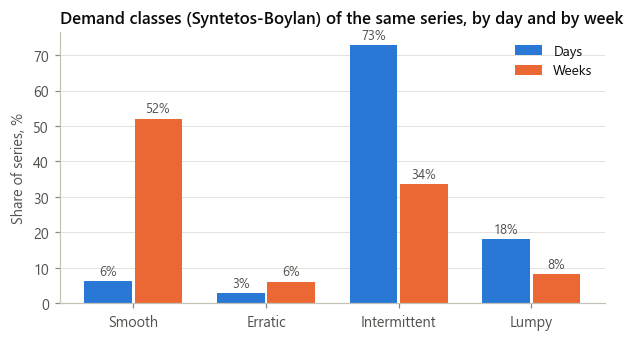

In [3]:
fig, ax = plt.subplots(figsize=(6.4, 3.2))
x = np.arange(len(cls))
for k, (col, color) in enumerate(zip(cls.columns, SERIES)):
    bars = ax.bar(x + (k - 0.5) * 0.38, 100 * cls[col], 0.36, color=color, label=col.capitalize())
    ax.bar_label(bars, fmt="%.0f%%", fontsize=8.5, color=INK_SECONDARY, padding=2)
ax.set_xticks(x, [c.capitalize() for c in cls.index])
ax.set_ylabel("Share of series, %")
ax.set_title("Demand classes (Syntetos-Boylan) of the same series, by day and by week")
ax.legend()
savefig(fig, "classes_days_weeks", subdir="weekly")
plt.show()

At the daily level nine series in ten are intermittent or lumpy; summed to weeks, more than half are
smooth. The weekly problem is a different one: mostly regular demand with fewer zeros, which is why the
weekly model is trained with the squared-error loss rather than Tweedie.

## 2. Windows and the forecasting scheme

Each week of a window is forecast **one week ahead from the Sunday before it**, so a 4-week window has 4
origins, the same origins as the daily models use. All scores are computed on weekly sums: WRMSSE over 7
levels of the hierarchy with scales from the weekly history and the dollar weights of the daily evaluation
(`weekly.evaluator`).

In [4]:
cal = m5.load_calendar().set_index("d_num")["date"]
windows = {"earlier window 1": 261, "earlier window 2": 265, "earlier window 3": 269, "validation (tuning)": 273, "test": 277}
rows = []
for name, T in windows.items():
    first, last = W.week_days(T + 1)[0], W.week_days(T + 4)[1]
    rows.append({"window": name, "last training week": T, "from": cal[first].strftime("%d.%m.%Y"), "to": cal[last].strftime("%d.%m.%Y")})
pd.DataFrame(rows).set_index("window")

,last training week,from,to
window,,,
earlier window 1,261,01.02.2016,28.02.2016
earlier window 2,265,29.02.2016,27.03.2016
earlier window 3,269,28.03.2016,24.04.2016
validation (tuning),273,25.04.2016,22.05.2016
test,277,23.05.2016,19.06.2016


## 3. Inputs of the weekly model

The groups are those of the daily model, rebuilt from weekly sales: **L** lags of weekly sales, **E** calendar
and prices, **S** statistics of the history, **ID** identifiers. The model sees weekly sums only.

In [5]:
table = W.feature_table()
table.to_csv(RESULTS / "weekly_inputs.csv", index=False)
pd.set_option("display.max_colwidth", 120)
table

,feature,group,description
0,h,h,horizon: weeks from the origin week t to the target week
1,lag_1,L,sales in week t - 0
2,lag_2,L,sales in week t - 1
3,lag_3,L,sales in week t - 2
4,lag_4,L,sales in week t - 3
5,lag_5,L,sales in week t - 4
6,lag_6,L,sales in week t - 5
7,lag_7,L,sales in week t - 6
8,lag_8,L,sales in week t - 7
9,lag_9,L,sales in week t - 8
